## NEURAL NETWORK FROM SRATCH USING PYTHON

In [1]:

import pandas as pd 
from sklearn.model_selection import train_test_split

In [52]:

df = pd.read_csv("insurance_data.csv")
df

,age,affordibility,bought_insurance
0,22,1,0
1,25,0,0
2,47,1,1
3,52,0,0
4,46,1,1
5,56,1,1
6,55,0,0
7,60,0,1
8,62,1,1
9,61,1,1


In [3]:
x_train,x_test,y_train,y_test = train_test_split(df[["age","affordibility"]],df["bought_insurance"],test_size=0.2,random_state=42)
x_train

,age,affordibility
17,58,1
22,40,1
11,28,1
13,29,0
15,55,1
1,25,0
4,46,1
5,56,1
2,47,1
16,25,0


In [4]:
x_train_scaled = x_train/100
x_test_dup = x_test
x_test_scaled = x_test/100
x_train_scaled


,age,affordibility
17,0.58,0.01
22,0.40,0.01
11,0.28,0.01
13,0.29,0.00
15,0.55,0.01
1,0.25,0.00
4,0.46,0.01
5,0.56,0.01
2,0.47,0.01
16,0.25,0.00


In [5]:
import numpy as np
def sigmoid(x):
    return 1/(1+np.exp(-x))

In [6]:
sigmoid(0)

np.float64(0.5)

In [7]:
#This is done to handle any digit both positive and negative 
def log_loss(y_true, y_predicted):
    ep  = 1e-10
    y_predicted_new = [max(i,ep) for i in y_predicted]
    y_predicted_new = [min(i,1-ep) for i in y_predicted_new]
    y_predicted_new = np.array(y_predicted_new)
    return -np.mean(y_true*np.log(y_predicted_new)+(1-y_true)*np.log(1-y_predicted_new))

In [60]:
class MyNN:
    def __init__(self):        
        self.w1 = 1
        self.w2 = 1
        self.b = 0

    def fit(self, X, y, epochs):
       self.w1,self.w2,self.b = self.gradientdescent(X["age"],X["affordibility"],y,epochs)
        
    def predict(self,x_test):
        weighted_sum = self.w1*x_test["age"] + self.w2*x_test["affordibility"] + self.b
        return sigmoid(weighted_sum)
        
    def gradientdescent(self,age,affordibility,y,epochs):
        w1= w2 = 1
        b=0
        learning_rate = 0.01
        n = len(age)
        
        for i in range(epochs):
            weighted_sum = w1 * age+ w2 * affordibility + b
            y_predicted = sigmoid(weighted_sum)
            loss = log_loss(y, y_predicted)
            
           
            dw1= (1/n)*np.dot(np.transpose(age),(y_predicted-y)) 
            dw2 = (1/n)*np.dot(np.transpose(affordibility),(y_predicted-y))

            db = np.mean(y_predicted - y)

            w1 = w1 - learning_rate*dw1
            w2 = w2 - learning_rate*dw2
            b = b- learning_rate*db
            print (f'Epoch:{i}, w1:{w1}, w2:{w2}, b:{b}, loss:{loss}')
        return w1,w2,b
        



In [61]:
Model = MyNN()

In [62]:
Model.fit(x_train_scaled, y_train, epochs=1000)

Epoch:0, w1:1.0000105462867008, w2:0.9999999560528958, b:-0.0009819612633284152, loss:0.6701239501620915
Epoch:1, w1:1.0000220020830244, w2:0.9999999280242027, b:-0.0019615840037145818, loss:0.6700276285809859
Epoch:2, w1:1.0000343650317378, w2:0.9999999158730599, b:-0.002938874219105065, loss:0.6699317631125985
Epoch:3, w1:1.0000476327801429, w2:0.9999999195586874, b:-0.003913837895581612, loss:0.6698363513341827
Epoch:4, w1:1.000061802980078, w2:0.9999999390403854, b:-0.0048864810073555665, loss:0.669741390834959
Epoch:5, w1:1.0000768732879226, w2:0.9999999742775347, b:-0.0058568095167625695, loss:0.6696468792160654
Epoch:6, w1:1.000092841364599, w2:1.0000000252295966, b:-0.006824829374257556, loss:0.6695528140905086
Epoch:7, w1:1.0001097048755763, w2:1.000000091856113, b:-0.007790546518410027, loss:0.6694591930831155
Epoch:8, w1:1.0001274614908717, w2:1.0000001741167062, b:-0.008753966875899615, loss:0.6693660138304837
Epoch:9, w1:1.000146108885055, w2:1.0000002719710794, b:-0.00971

In [51]:
Model.predict(x_test_scaled)

9     0.584698
25    0.563707
8     0.587673
21    0.475695
0     0.465970
12    0.478755
dtype: float64

In [53]:
y_test

9     1
25    1
8     1
21    0
0     0
12    0
Name: bought_insurance, dtype: int64

In [63]:
import matplotlib.pyplot as plt

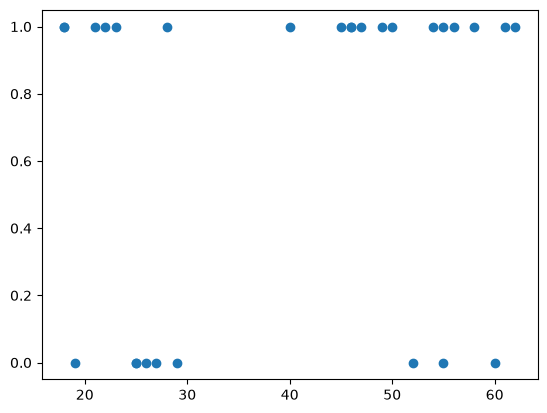

In [65]:
plt.scatter(df['age'],df["affordibility"])